In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from tqdm import tqdm

from utils.complex_param import complex_param_perturbated, de_phase_solution
from utils.fourth_order_runge_kuta import rk_interval
from utils.model import cosine_kernel_fft, kuramoto_kernel, vf_r_theta
from utils.plotting_utils import generate_yticks_and_labels
from utils.self_consistency import self_consistency_rewrite_root

BASE_FOLDER = Path("./paper_plots")
BASE_FOLDER.mkdir(parents=True, exist_ok=True)

In [2]:
N = 1024
A = 0.995
alpha = (np.pi / 2) - 0.16
kernel_fft = cosine_kernel_fft(A, N)

omegas = np.zeros(N)

np.random.seed(seed=1338)

evolve_time = 1100.0
dt = 0.1
beta_positions = [N // 4, 3 * N // 4]
dirac_amplitude = 0.1
initial_conditions = (
    6.0
    * np.exp(-0.76 * (np.linspace(-np.pi, np.pi, N, endpoint=False)) ** 2)
    * (np.random.random(N) - 0.5)
)

In [3]:
kuramoto = kuramoto_kernel(omegas, kernel_fft, alpha=alpha)
t_evolve_eval = np.arange(0, evolve_time + dt, dt)
t_evolve_span = (0, evolve_time + dt)

sol = solve_ivp(
    lambda _, y: kuramoto(y),
    t_evolve_span,
    initial_conditions,
    t_eval=t_evolve_eval,
    method="RK45",
    rtol=1e-7,
    atol=1e-10,
)
init_state = sol.y.T

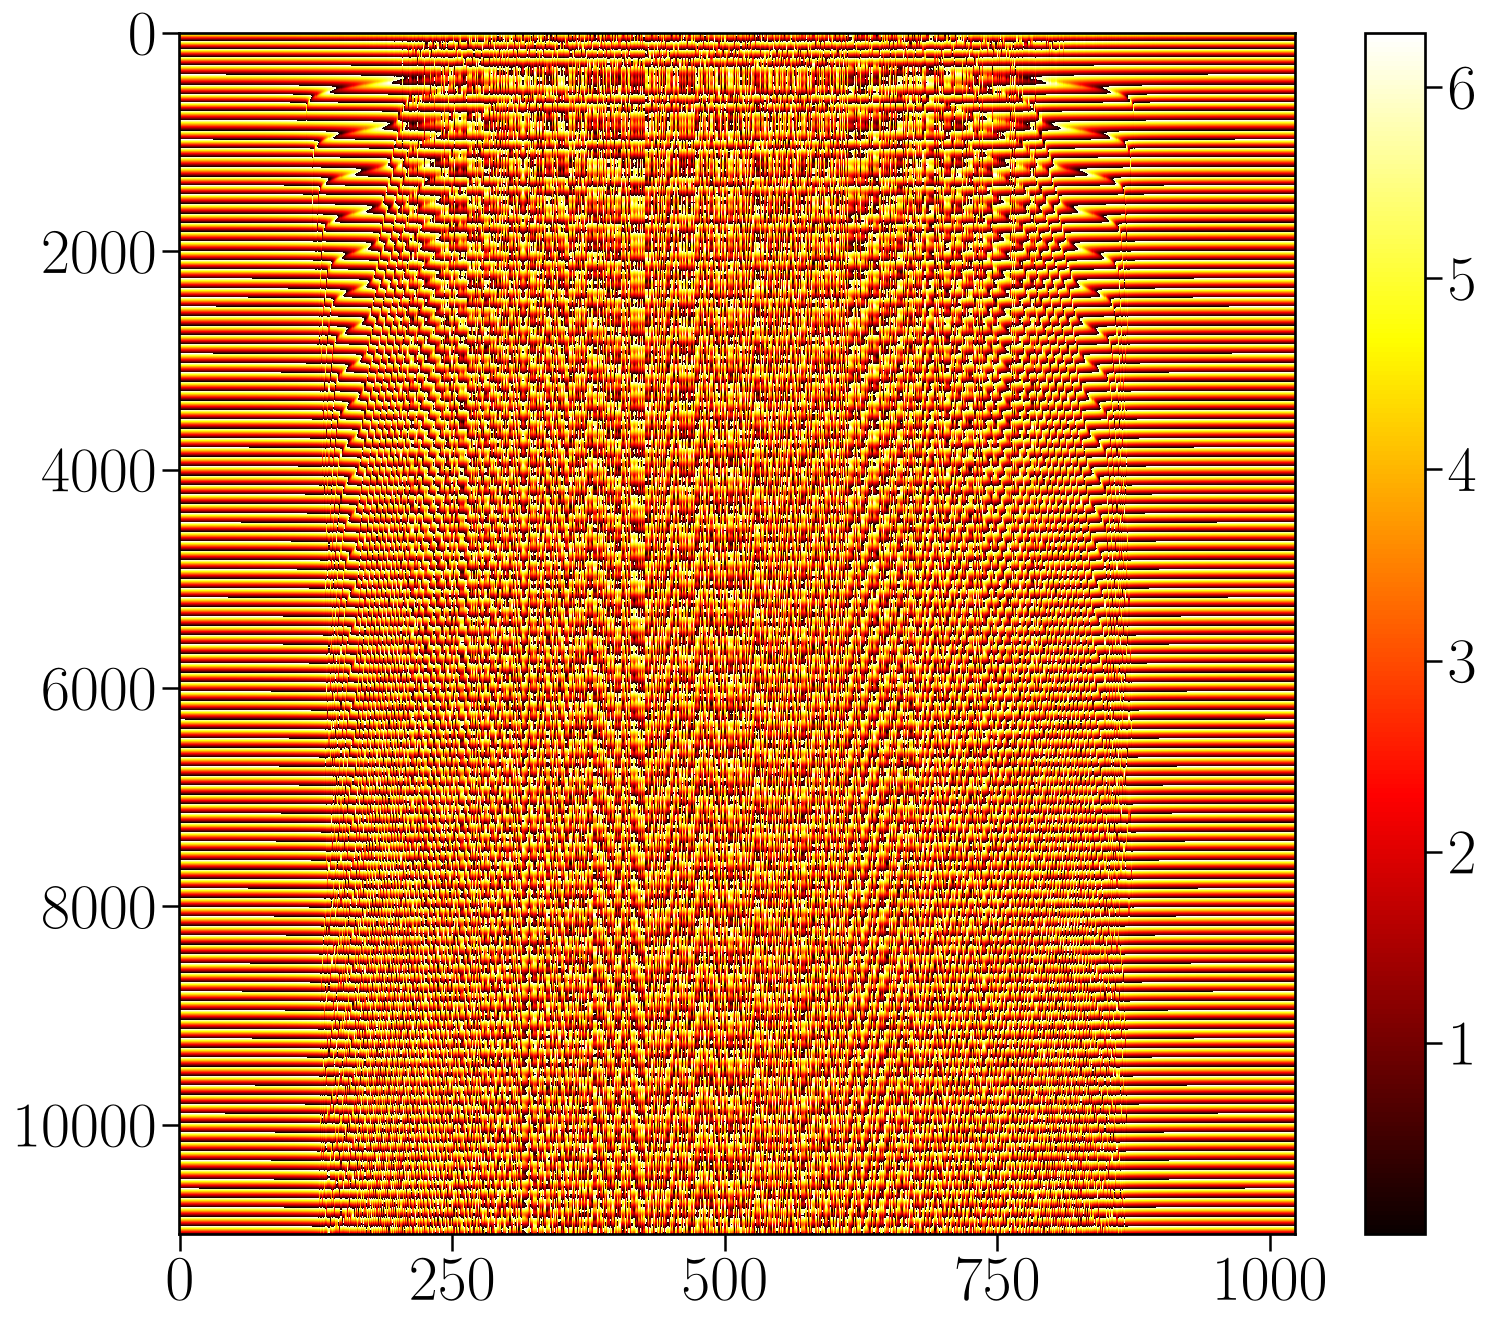

In [4]:
plt.figure()
heatmap = plt.imshow(
    init_state % (2 * np.pi), aspect="auto", interpolation="none", cmap="hot"
)
plt.colorbar(heatmap)
plt.show()

In [5]:
solutions = []
for beta in tqdm(beta_positions):
    new_omegas = omegas.copy()
    new_omegas[beta - 10 : beta + 10] += dirac_amplitude
    kuramoto = kuramoto_kernel(new_omegas, kernel_fft, alpha=alpha)
    t_evolve_eval = np.arange(0, evolve_time * 15 + dt, dt)
    t_evolve_span = (0, evolve_time * 15 + dt)
    sol = solve_ivp(
        lambda t, y: kuramoto(y),
        t_evolve_span,
        init_state[-1],
        t_eval=t_evolve_eval,
        method="RK45",
        rtol=1e-7,
        atol=1e-10,
    )
    solutions.append(sol)

100%|██████████| 2/2 [00:20<00:00, 10.15s/it]


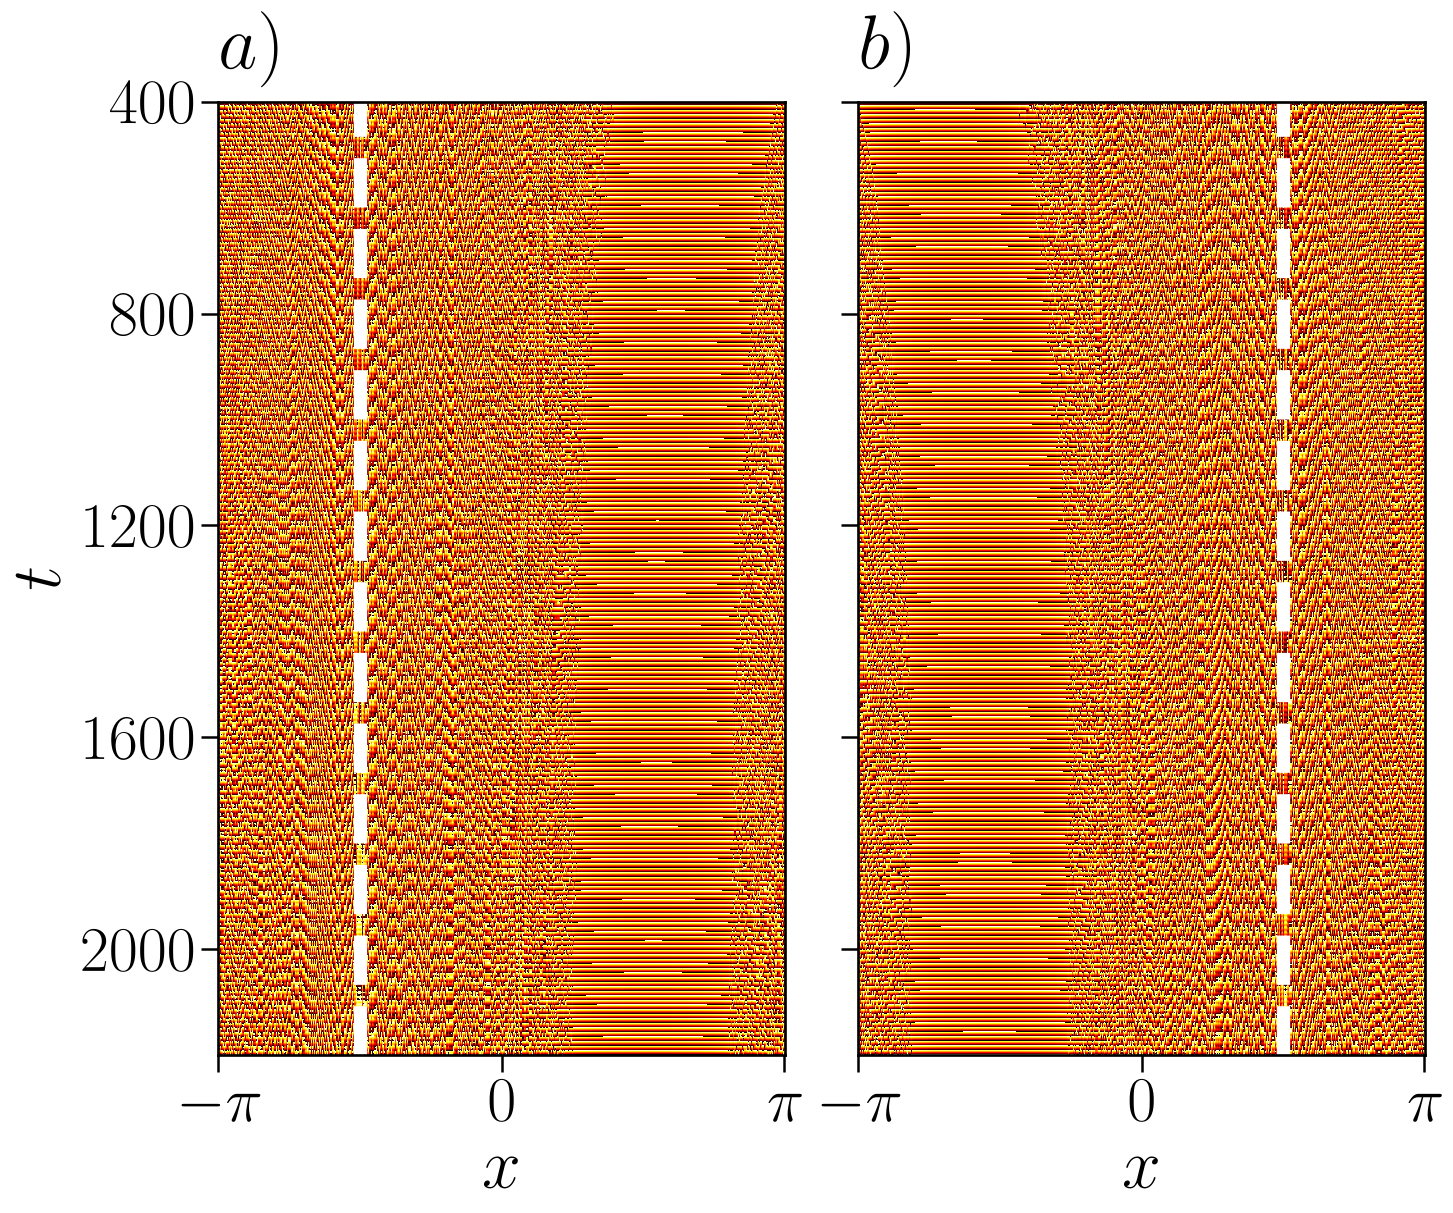

In [6]:
titles = [r"$a)$", r"$b)$", r"$c)$", r"$d)$"]
fig, ax = plt.subplots(1, 2, figsize=(12, 10), layout="constrained", sharey="row")

start_time = 400
end_time = 2200

for i, sol in enumerate(solutions):
    time = sol.t
    state = sol.y.T
    forcing_location = beta_positions[i]

    # Find the indices corresponding to the time bounds
    start_idx = np.searchsorted(time, start_time)
    end_idx = np.searchsorted(time, end_time)

    # Extract time and state within bounds
    time_bounds = time[start_idx:end_idx]
    state_bounds = state[start_idx:end_idx]

    # Set yticks to show times spaced by 100 units
    yticks = np.arange(
        start_time, end_time + 1, 400
    )  # Time values from 1000 to 1800 with step of 100
    ytick_indices = [
        np.searchsorted(time_bounds, t) for t in yticks
    ]  # Map time to indices

    # Plot the heatmap
    heatmap = ax.flatten()[i].imshow(
        state_bounds % (2 * np.pi), aspect="auto", cmap="hot", interpolation="nearest"
    )
    ax.flatten()[i].set_yticks(ytick_indices)
    ax.flatten()[i].set_yticklabels([f"{t:.0f}" for t in yticks])

    if i == 0:
        ax.flatten()[i].set_ylabel(r"$t$")

    ax.flatten()[i].set_xlabel(r"$x$")
    ax.flatten()[i].set_title(titles[i], loc="left")

    ax.flatten()[i].set_xticks([0, N / 2, N - 1])
    ax.flatten()[i].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])
    # ax.flatten()[i].set_xticks([0, N // 4, N / 2, 3 * N / 4, N - 1])
    # ax.flatten()[i].set_xticklabels([r"$-\pi$", r'$-\frac{\pi}{2}$', r"$0$", r'$\frac{\pi}{2}$',r"$\pi$"])

    ax.flatten()[i].axvline(
        x=forcing_location, color="white", linestyle="--", linewidth=8
    )


# plt.savefig(BASE_FOLDER / "2.pdf")
plt.show()

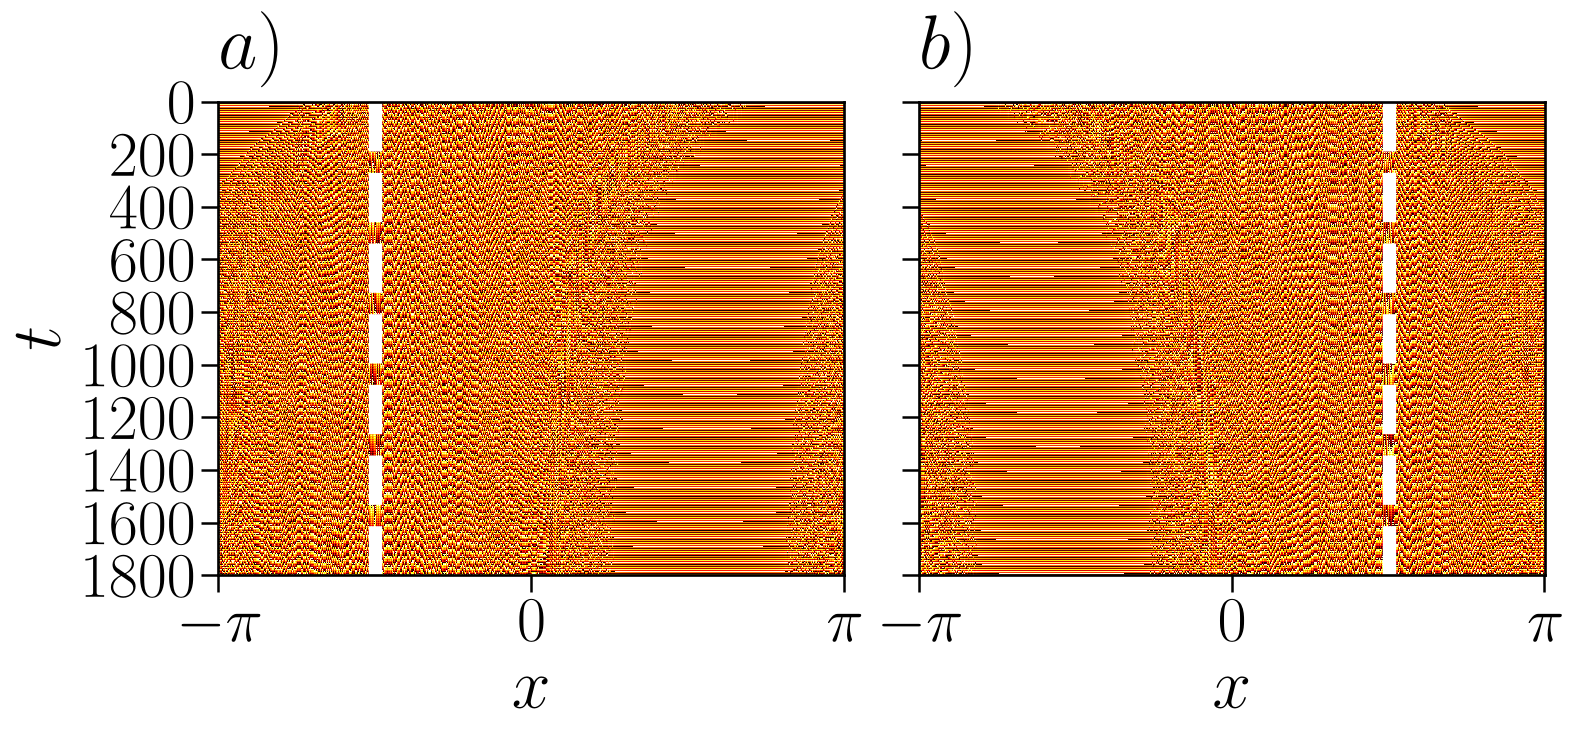

In [7]:
titles = [r"$a)$", r"$b)$", r"$c)$", r"$d)$"]
fig, ax = plt.subplots(1, 2, figsize=(13, 6), layout="constrained", sharey="row")
for i, sol in enumerate(solutions):
    evolve_time = sol.t[:18000][-1]
    state = sol.y.T[:18000]
    forcing_location = beta_positions[i]
    yticks, ytick_labels = generate_yticks_and_labels(sol, evolve_time, every_n=200)

    heatmap = ax.flatten()[i].imshow(
        state % (2 * np.pi), aspect="auto", cmap="hot", interpolation="nearest"
    )

    ax.flatten()[i].axvline(
        x=forcing_location, color="white", linestyle="--", linewidth=8
    )
    ax.flatten()[i].set_yticks(yticks, ytick_labels)

    if i == 0:
        ax.flatten()[i].set_ylabel(r"$t$")

    ax.flatten()[i].set_xlabel(r"$x$")
    ax.flatten()[i].set_title(titles[i], loc="left")

    ax.flatten()[i].set_xticks([0, N / 2, N - 1])
    ax.flatten()[i].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

# plt.savefig(BASE_FOLDER / "2.pdf")
plt.show()

In [ ]:
## DOUBLE  HEATMAP with splitting the first and last 500 points kinda does not look good!
# def generate_manual_yticks_and_labels(sol, first_500, last_500, every_n=50):
#     # Extract time segments
#     time_first = sol.t[first_500]
#     time_last = sol.t[last_500]

#     # Combine the two time segments
#     combined_time = np.concatenate((time_first, time_last))

#     # Generate y-ticks for the combined time
#     total_points = len(combined_time)
#     yticks = list(range(0, total_points, every_n))

#     # Generate corresponding labels
#     labels_first = [f"{t:.1f}" for t in time_first[::every_n]]
#     labels_last = [f"{t:.1f}" for t in time_last[::every_n]]
#     ytick_labels = labels_first + labels_last

#     return yticks, ytick_labels

# titles = [r"$a)$", r"$b)$"]
# fig, ax = plt.subplots(1, 2, layout="constrained", dpi=50, sharey="row")
# for i, sol in enumerate(solutions):
#     first_500 = slice(0, 10000)
#     last_500 = slice(-1000, None)
#     yticks, ytick_labels = generate_manual_yticks_and_labels(sol, first_500, last_500, every_n=1000)

#     # Concatenate time and state slices
#     combined_time = np.concatenate((sol.t[first_500], sol.t[last_500]))
#     combined_state = np.vstack((sol.y.T[first_500], sol.y.T[last_500]))

#     # Generate yticks and labels for the concatenated time
#     # yticks, ytick_labels = generate_yticks_and_labels(sol, combined_time, every_n=100)

#     # Plot heatmap
#     heatmap = ax[i].imshow(
#         combined_state % (2 * np.pi), aspect="auto", cmap="hot", interpolation="nearest"
#     )

#     # Add a vertical line for the forcing location
#     ax[i].axvline(x=beta_positions[i], color="white", linestyle="--", linewidth=6)

#     # Set yticks, xticks, labels, and title
#     ax[i].set_yticks(yticks)
#     ax[i].set_yticklabels(ytick_labels)
#     ax[i].set_xlabel(r"$x$")
#     ax[i].set_title(titles[i], loc="left")
#     ax[i].set_xticks([0, N // 2, N - 1])
#     ax[i].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])


# plt.savefig(BASE_FOLDER / "2.pdf")
# plt.show()

True A solution was found at the specified tolerance.
True A solution was found at the specified tolerance.


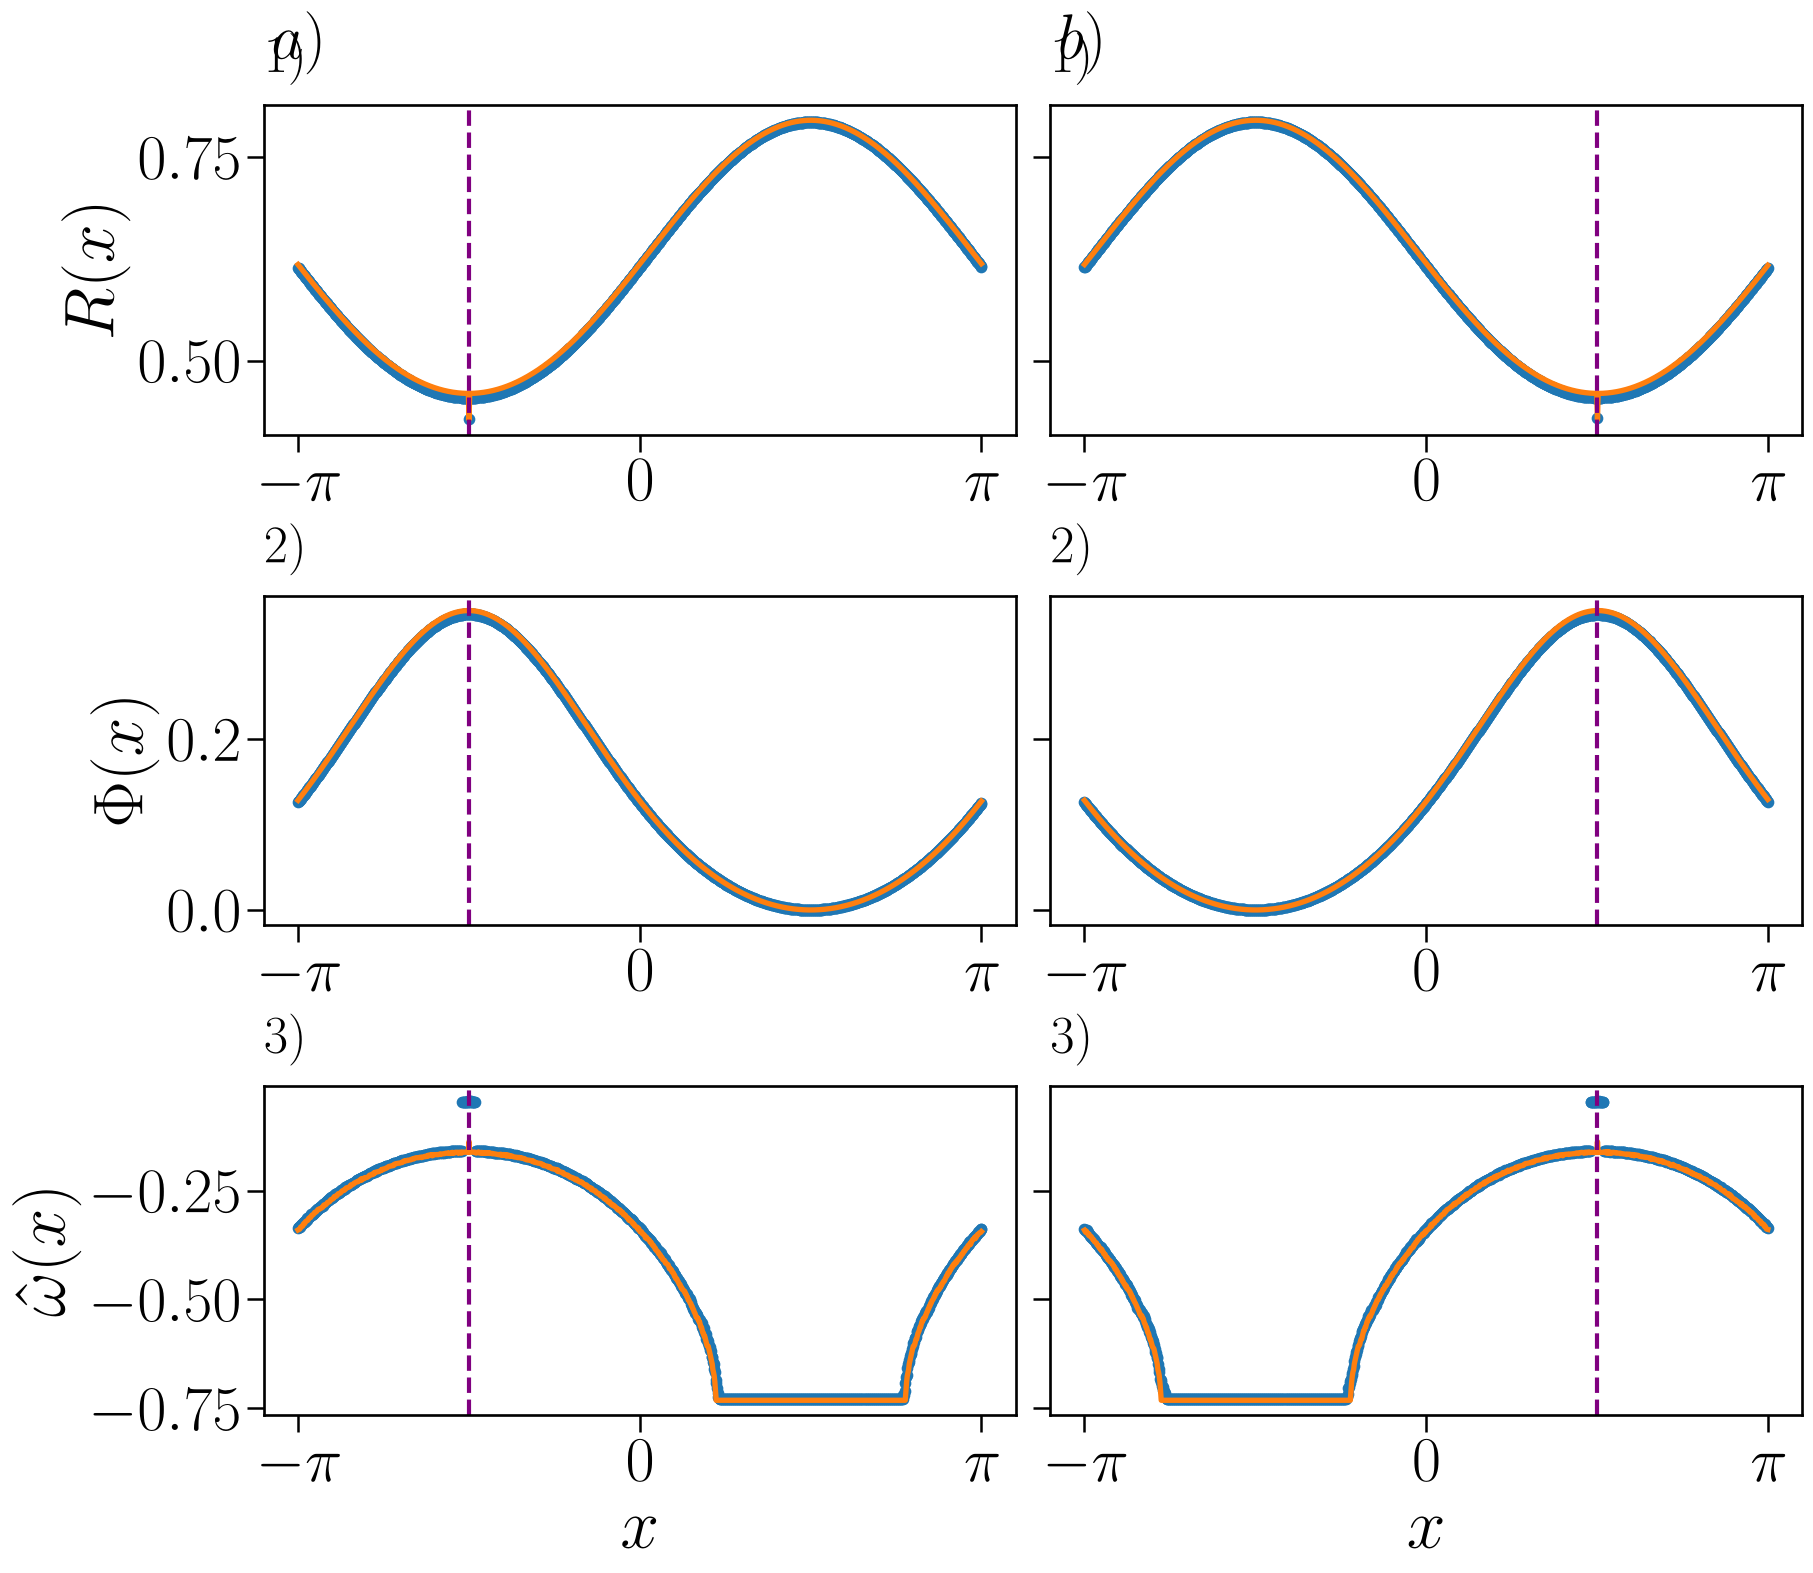

In [9]:
fig, axs = plt.subplots(3, 2, constrained_layout=True, sharey="row")
titles = [r"$a)$", r"$b)$", r"$c)$", r"$d)$"]

big_omegas = []
for i, ax_col in enumerate(axs.T):  # Loop over columns
    ax_col[0].set_title(titles[i], loc="left", fontsize="large")
    ax_col[0].text(-40, 0.93, titles[i], verticalalignment="top", rotation=0)

    sol = solutions[i]
    forcing_location = beta_positions[i]
    epsh_func = omegas.copy()
    epsh_func[forcing_location] += dirac_amplitude
    init_state = sol.y.T[-20000:]

    z = complex_param_perturbated(kernel_fft, init_state, epsh_func, alpha)
    # z = complex_param(N, kernel, init_state)

    r_orig = np.mean(np.abs(z), axis=0)
    theta_orig = np.unwrap(np.unwrap(np.angle(z), axis=0).mean(axis=0))
    theta_orig = theta_orig - np.min(theta_orig)

    unwrap_state = np.unwrap(init_state, axis=0)
    omega_real = (np.diff(unwrap_state, axis=0)).mean(axis=0) / 0.1

    r_sol, theta_sol, Omega, root_result = self_consistency_rewrite_root(
        r_orig,
        theta_orig,
        np.min(omega_real),
        kernel_fft,
        0.0,
        epsh_func,
        alpha,
        options={},
    )
    print(root_result.success, root_result.message)
    big_omegas.append(Omega)

    new_initial_conditions = init_state[-1] % (2 * np.pi)
    model = vf_r_theta(omegas, Omega, r_sol, theta_sol, alpha)
    sim_state = rk_interval(new_initial_conditions, model, 1000.0, dt)
    sim_state = sim_state[1000:, :]

    state_sim = np.unwrap(sim_state, axis=0)
    omega_sim = (np.diff(state_sim, axis=0)).mean(axis=0) / dt

    # Subplots for r(x), theta(x), and omega(x)
    ax_col[0].scatter(np.arange(N), r_orig)
    ax_col[0].plot(np.arange(N), r_sol, c="tab:orange")
    ax_col[0].set_title(r"$1)$", fontsize="small", loc="left")
    ax_col[0].set_xticks([0, N / 2, N - 1])
    ax_col[0].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

    ax_col[1].scatter(np.arange(N), theta_orig)
    ax_col[1].plot(np.arange(N), theta_sol, c="tab:orange")
    ax_col[1].set_title(r"$2)$", fontsize="small", loc="left")
    ax_col[1].set_xticks([0, N / 2, N - 1])
    ax_col[1].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

    ax_col[2].scatter(np.arange(N), omega_real)
    ax_col[2].plot(np.arange(N), omega_sim + Omega, c="tab:orange")
    ax_col[2].set_xlabel(r"$x$")
    ax_col[2].set_title(r"$3)$", fontsize="small", loc="left")
    ax_col[2].set_xticks([0, N / 2, N - 1])
    ax_col[2].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

    # TO GO TO THE ORIGINAL PLOT REMOVE THE IF STATEMENT AND REMOVE SHAREY
    if i == 0:
        ax_col[0].set_ylabel(r"$R(x)$")
        ax_col[1].set_ylabel(r"$\Phi(x)$")
        ax_col[2].set_ylabel(r"$\hat{\omega}(x)$")

    ax_col[0].axvline(x=forcing_location, color="purple", linestyle="--", lw=2.5)
    ax_col[1].axvline(x=forcing_location, color="purple", linestyle="--", lw=2.5)
    ax_col[2].axvline(x=forcing_location, color="purple", linestyle="--", lw=2.5)


plt.savefig(BASE_FOLDER / "5.pdf")
plt.show()

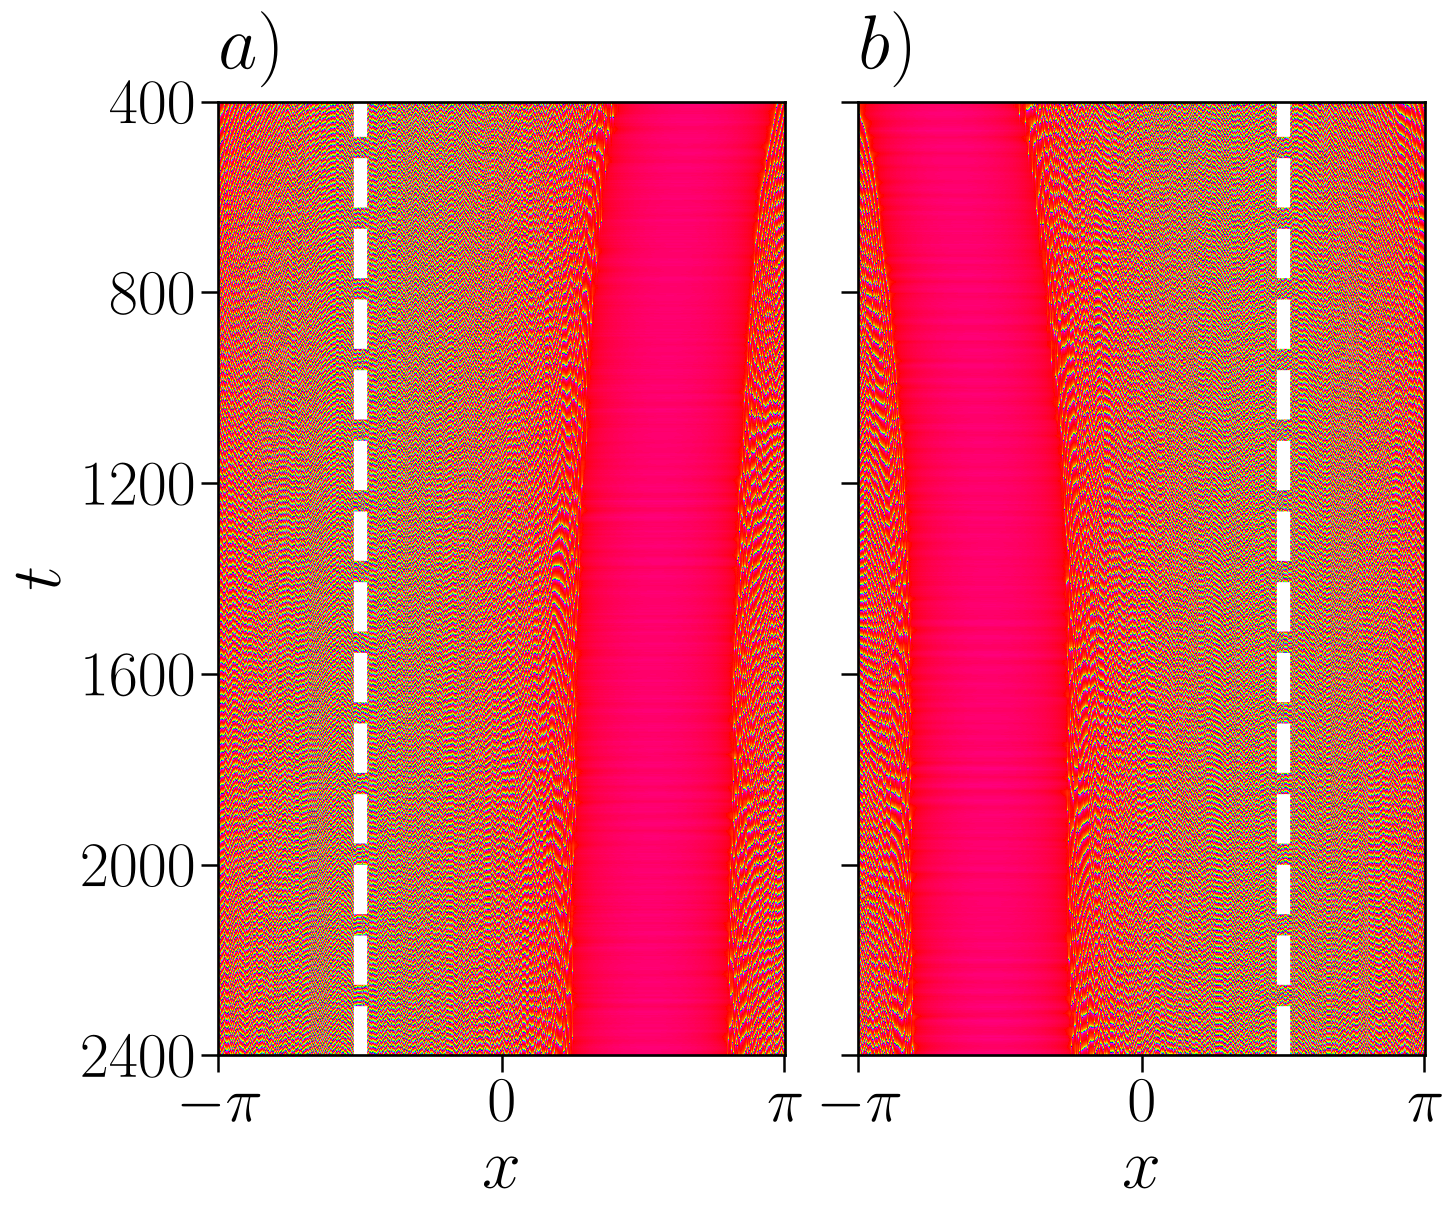

In [10]:
titles = [r"$a)$", r"$b)$", r"$c)$", r"$d)$"]
fig, ax = plt.subplots(1, 2, figsize=(12, 10), layout="constrained", sharey="row")

start_time = 400
end_time = 2400

for i, sol in enumerate(solutions):
    time = sol.t
    state = sol.y.T
    forcing_location = beta_positions[i]

    # Find the indices corresponding to the time bounds
    start_idx = np.searchsorted(time, start_time)
    end_idx = np.searchsorted(time, end_time)

    # Extract time and state within bounds
    time_bounds = time[start_idx:end_idx]
    state_bounds = state[start_idx:end_idx]

    # Set yticks to show times spaced by 100 units
    yticks = np.arange(
        start_time, end_time + 1, 400
    )  # Time values from 1000 to 1800 with step of 100
    ytick_indices = [
        np.searchsorted(time_bounds, t) for t in yticks
    ]  # Map time to indices

    constant_phase = de_phase_solution(state_bounds)
    if i == 0:
        constant_phase = constant_phase - constant_phase[-1, -N // 4]
    if i == 1:
        constant_phase = constant_phase - constant_phase[-1, N // 4]

    heatmap = ax.flatten()[i].imshow(
        constant_phase,
        aspect="auto",
        cmap="hsv",
        interpolation="nearest",
    )
    ax.flatten()[i].set_yticks(ytick_indices)
    ax.flatten()[i].set_yticklabels([f"{t:.0f}" for t in yticks])

    if i == 0:
        ax.flatten()[i].set_ylabel(r"$t$")

    ax.flatten()[i].set_xlabel(r"$x$")
    ax.flatten()[i].set_title(titles[i], loc="left")

    ax.flatten()[i].set_xticks([0, N / 2, N - 1])
    ax.flatten()[i].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])
    # ax.flatten()[i].set_xticks([0, N // 4, N / 2, 3 * N / 4, N - 1])
    # ax.flatten()[i].set_xticklabels([r"$-\pi$", r'$-\frac{\pi}{2}$', r"$0$", r'$\frac{\pi}{2}$',r"$\pi$"])

    ax.flatten()[i].axvline(
        x=forcing_location, color="white", linestyle="--", linewidth=8
    )


plt.savefig(BASE_FOLDER / "2.pdf")
plt.show()